# QSWAT+ and ML hybrid streamflow forecasting

**Data integration:** daily climate means from five meteorological stations were joined by date to observed streamflow and historical QSWAT+ simulated discharge. QSWAT+ discharge is included as a predictor in Random Forest, XGBoost, LightGBM, and LSTM and as a direct level-0 feature in the Ridge stacking model. Predictors include 1- and 7-day precipitation and flow lags, 7-day rolling means, and calendar variables. The LSTM scaler is fit on calibration data only.

**Chronological calibration and validation:** the overlapping records cover 1988–2011. After the 7-day feature warm-up, 1988-01-08 through 2002-12-31 (5,472 records) are used for calibration/training; 2003-01-01 through 2011-12-31 (3,287 records) are held out for temporal validation. No validation records are used for model fitting or hyperparameter selection. Randomized hyperparameter search and three-fold expanding-window TimeSeriesSplit CV are restricted to calibration. Out-of-fold predictions train the Ridge stack; its CV alpha selection is nested within the calibration folds.

**Future scenario flow:** daily QSWAT+ `flo_out` was extracted from the four provided SWAT+ databases. It uses channel `cha001`, which had the highest mean `flo_out` in the supplied monthly channel summaries, taking SSPN runs for 2015–2044 and SSPM runs from 2045–2074 to avoid overlap. These flows are merged with the six-model CMIP6 precipitation ensemble and CanESM5 temperature for SSP245 and SSP585. Future hybrid flow lags are updated recursively.

**BMA assessment:** BMA component weights are estimated as a Gaussian predictive mixture using only the calibration-period out-of-fold predictions. Its expected-flow estimate is evaluated separately on the independent 2003–2011 validation period. Table X reports calibration training, fold-wise time-series CV, and independent validation scores for each model.

Chronological calibration-CV and independent validation metrics
                                     R2     NSE  ...      MAE  PBIAS_percent
Stacking CV (1988-2002)          0.9441  0.9441  ...  10.3610        -1.0378
Stacking Validation (2003-2011)  0.9593  0.9593  ...   8.2042        -0.0679
BMA Validation (2003-2011)       0.9590  0.9590  ...   8.3968        -0.9426

[3 rows x 5 columns]
Table X: training, time-series CV (mean +/- SD), and independent validation
                Model  ...                                            Remarks
0              QSWAT+  ...                                Process-based model
1              QSWAT+  ...                                 Independent period
2                  RF  ...                       Fitted on calibration period
3                  RF  ...                 Mean ± SD across 3 expanding folds
4                  RF  ...                                 Independent period
5             XGBoost  ...                       Fitted on cal

Evaluation,R2,NSE,RMSE,MAE,PBIAS_percent
Stacking CV (1988-2002),0.944102,0.944102,22.184114,10.360980,-1.037790
Stacking Validation (2003-2011),0.959260,0.959260,17.619622,8.204210,-0.067859
BMA Validation (2003-2011),0.958994,0.958994,17.677108,8.396751,-0.942637


Model,Stage,Period,R²,NSE,RMSE,MAE,Remarks
QSWAT+,Calibration,1988-2002,0.6592979562409931,0.6592979562409931,52.41424259389173,38.32633269078947,Process-based model
QSWAT+,Validation,2003-2011,0.6237595541941564,0.6237595541941564,53.54525108213286,38.62158744234864,Independent period
RF,Training,1988-2002,0.9881387058869395,0.9881387058869395,9.779755166556548,3.780214492367783,Fitted on calibration period
RF,Time-series CV,1988-2002,0.9469 ± 0.0095,0.9469 ± 0.0095,20.3968 ± 4.8483,9.3608 ± 2.4422,Mean ± SD across 3 expanding folds
RF,Validation,2003-2011,0.9566968750660526,0.9566968750660526,18.165520161704222,8.426256429319468,Independent period
XGBoost,Training,1988-2002,0.9750331029525128,0.9750331029525128,14.188753058119321,6.997423898118228,Fitted on calibration period
XGBoost,Time-series CV,1988-2002,0.9495 ± 0.0071,0.9495 ± 0.0071,19.8830 ± 4.3927,9.7425 ± 1.9858,Mean ± SD across 3 expanding folds
XGBoost,Validation,2003-2011,0.9575603618714674,0.9575603618714674,17.98349321025318,8.448100863380636,Independent period
LightGBM,Training,1988-2002,0.976674540904429,0.976674540904429,13.714407361617749,6.431394954673284,Fitted on calibration period
LightGBM,Time-series CV,1988-2002,0.9473 ± 0.0077,0.9473 ± 0.0077,20.2935 ± 4.4785,9.8711 ± 2.1170,Mean ± SD across 3 expanding folds


Model,R2_mean,R2_std,NSE_mean,NSE_std,RMSE_mean,RMSE_std,MAE_mean,MAE_std
Random Forest,0.946864,0.009455,0.946864,0.009455,20.396815,4.848290,9.360796,2.442161
XGBoost,0.949461,0.007062,0.949461,0.007062,19.883047,4.392696,9.742502,1.985771
LightGBM,0.947322,0.007705,0.947322,0.007705,20.293476,4.478472,9.871078,2.117018
LSTM,0.466056,0.595006,0.466056,0.595006,56.053360,28.613632,40.367693,22.377849
Stacking Ensemble,0.944379,0.007261,0.944379,0.007261,22.004331,3.452026,10.360980,1.824250


Model,Weight,Residual_variance
QSWAT_Pred,0.020626,2786.355352
RF_Pred,0.423371,3.384262
XGB_Pred,0.289688,38.980214
LightGBM_Pred,0.251101,485.117732
LSTM_Pred,0.015214,13658.751911


Model,Best_CV_R2,Best_parameters
rf,0.946864,"{'n_estimators': 220, 'min_samples_leaf': 2, 'max_features': 1.0, 'max_depth': None}"
xgb,0.949461,"{'subsample': 1.0, 'n_estimators': 320, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 1.0}"
lgbm,0.947322,"{'num_leaves': 31, 'n_estimators': 220, 'min_child_samples': 30, 'learning_rate': 0.025}"


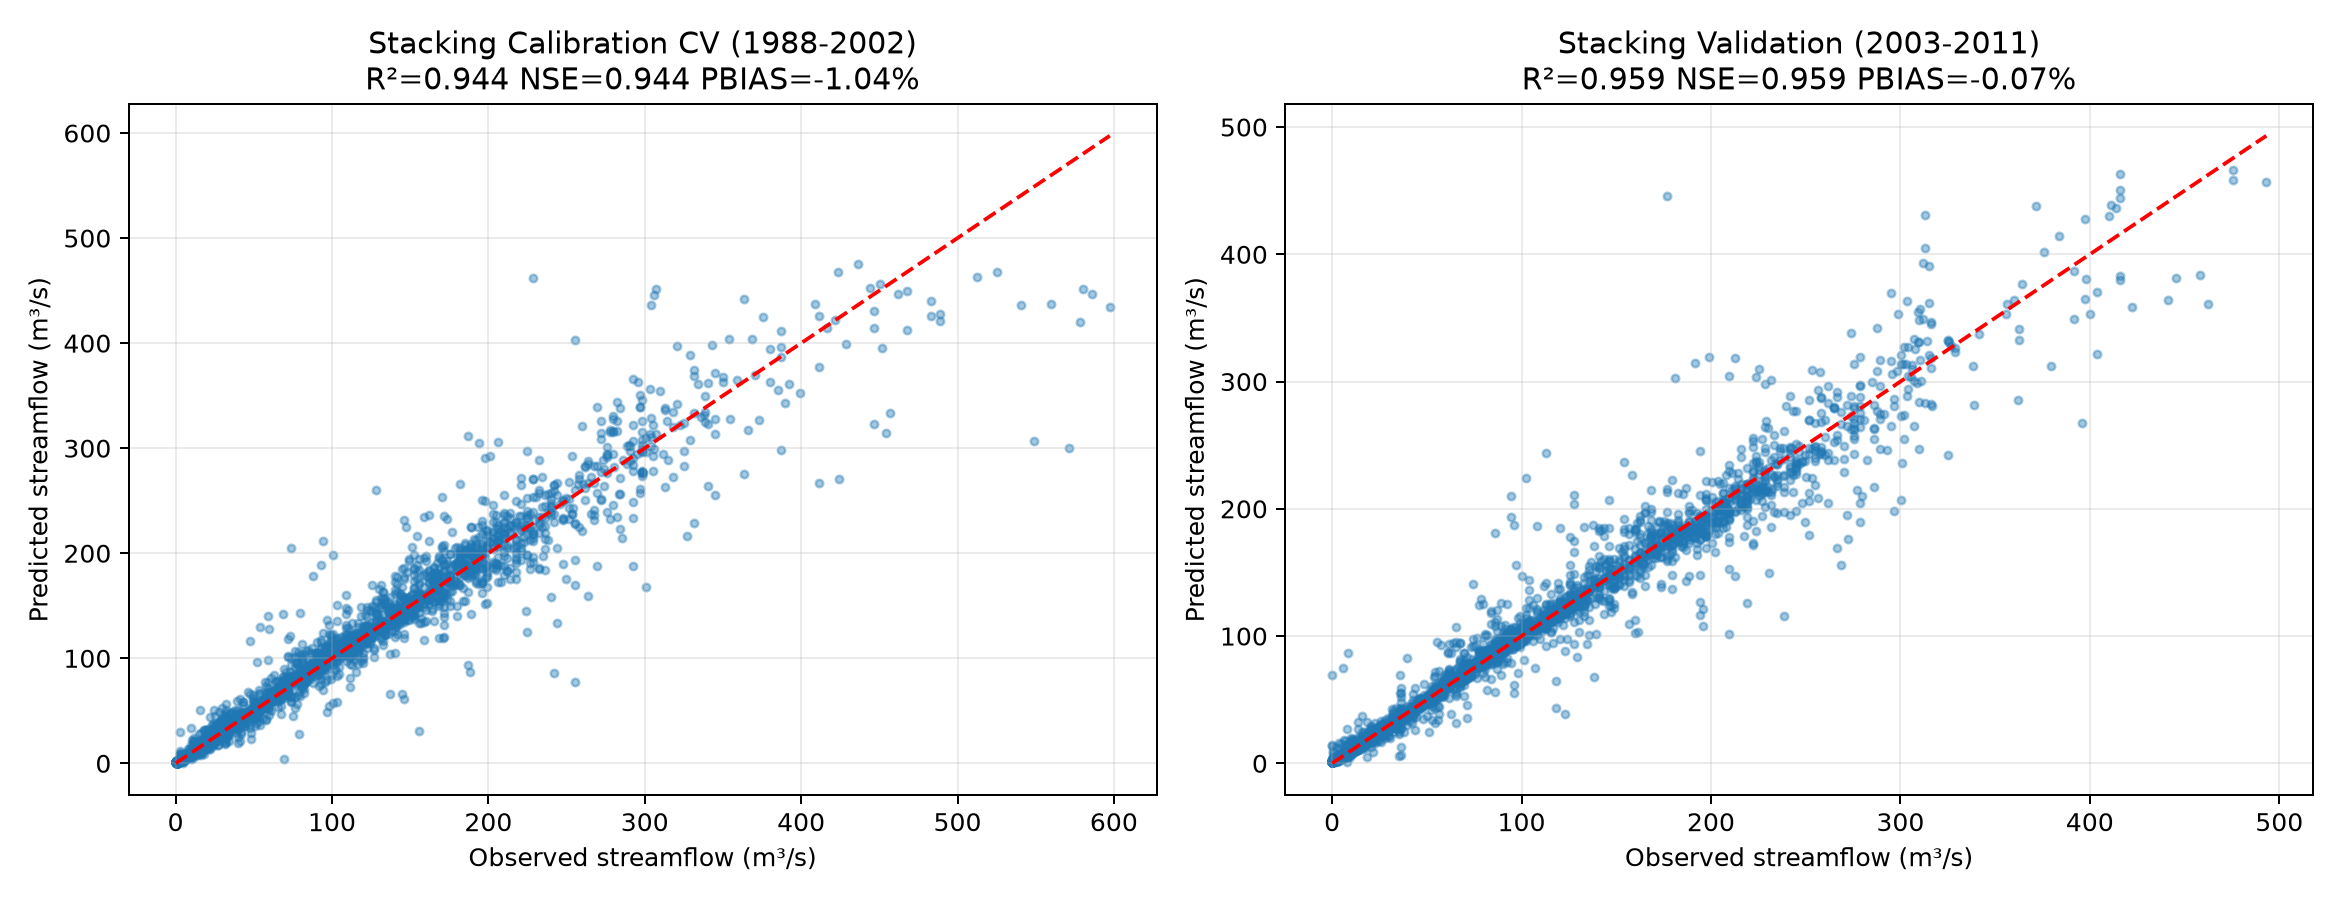

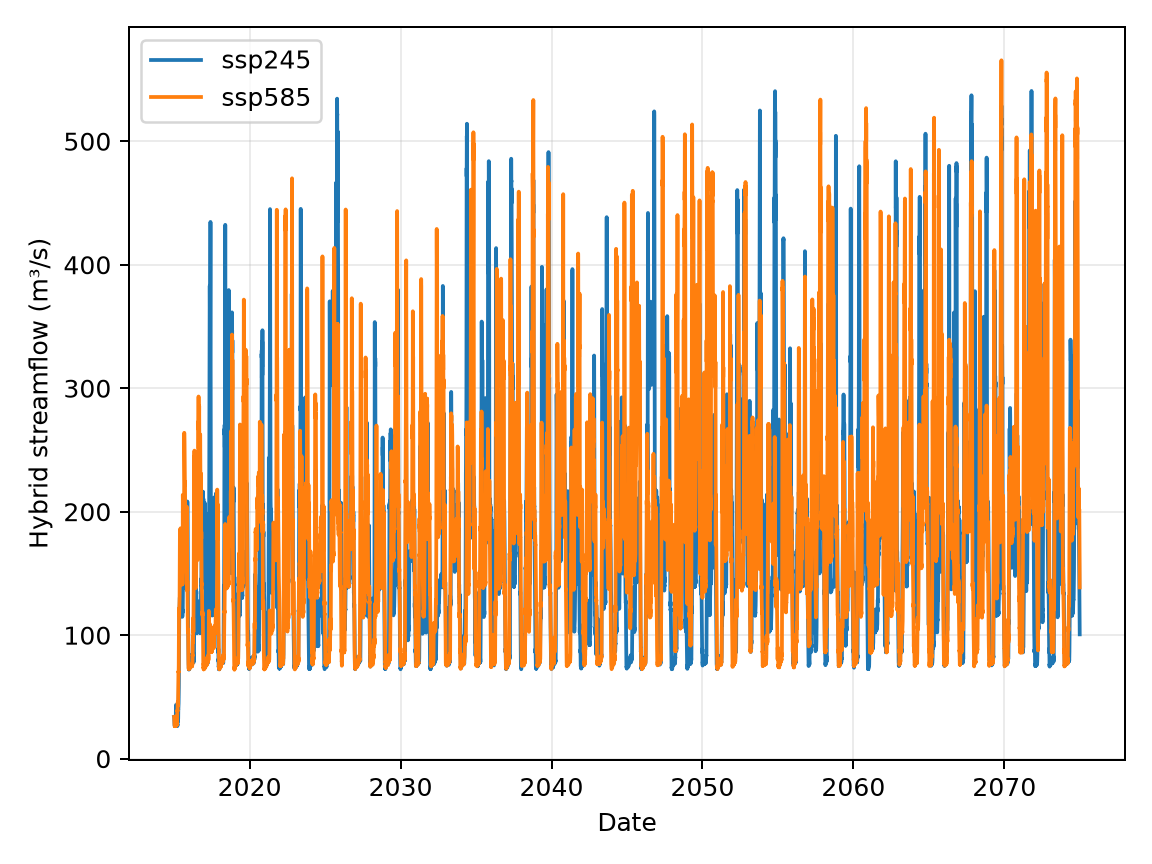

In [1]:
# Display the completed run. If model outputs are absent, run the workflow with this notebook's Python environment.
from pathlib import Path
import sys
import subprocess
import pandas as pd
from IPython.display import display, Image

root = Path.cwd()
out = root / 'hybrid_outputs'
python = sys.executable
script = root / 'hybrid_qswat_cmip6_workflow.py'
if not (out / 'hybrid_models.joblib').exists():
    if not script.exists():
        raise FileNotFoundError('Open this notebook from the project directory so hybrid_qswat_cmip6_workflow.py is available.')
    result = subprocess.run([python, str(script)], cwd=str(root), text=True, capture_output=True)
    print(result.stdout)
    if result.stderr: print(result.stderr)
    if result.returncode: raise RuntimeError(f'Workflow stopped with exit code {result.returncode}')

print('Chronological calibration-CV and independent validation metrics')
display(pd.read_csv(out / 'calibration_validation_metrics.csv', index_col=0).round(4))
print('Table X: training, time-series CV (mean +/- SD), and independent validation')
display(pd.read_csv(out / 'model_performance_table.csv'))
print('Three-fold expanding-window CV details within calibration')
display(pd.read_csv(out / 'cross_validation_results.csv').round(4))
print('Calibration-only BMA component weights')
display(pd.read_csv(out / 'bma_weights.csv').round(4))
print('Calibration-only randomized hyperparameter search')
display(pd.read_csv(out / 'hyperparameter_search_results.csv'))
display(Image(filename=str(out / 'calibration_validation_scatter.png')))
for scenario in ('ssp245', 'ssp585'):
    climate = pd.read_csv(out / f'cmip6_six_model_climate_ensemble_{scenario}.csv')
    forecast = pd.read_csv(out / f'future_cmip6_hybrid_streamflow_{scenario}.csv', parse_dates=['date'])
    print(scenario, len(climate), 'climate days;', len(forecast), 'hybrid-flow days;', forecast.date.min().date(), 'to', forecast.date.max().date())
    decade_start = 2015 + ((forecast.date.dt.year - 2015) // 10) * 10
    summary = forecast.groupby(decade_start).Hybrid_Predicted_Flow.agg(['mean','min','max']).round(2)
    summary.index = [f'{int(y)}-{min(int(y)+9, 2074)}' for y in summary.index]
    display(summary)
display(Image(filename=str(out / 'future_cmip6_streamflow.png')))
print('Validation model predictions:', out / 'model_validation_predictions.csv')
print('Calibration-CV and validation predictions:', out / 'chronological_calibration_validation_predictions.csv')
print('Saved chronological model, climate ensemble, and future flow outputs in', out)


## Outputs

The workflow saves chronological calibration-CV and independent validation metrics, three-fold expanding-window CV scores, hyperparameter results, trained models, and observed-versus-predicted plots. It also saves daily six-model climate ensembles and daily recursive hybrid streamflow projections for SSP245 and SSP585. QSWAT+ discharge is taken from channel `cha001` in m³/s.

Table X reports RMSE and MAE in the observed flow units (m³/s). Cross-validation rows contain the mean and sample standard deviation across the three chronological folds. BMA weights are fitted to calibration-only out-of-fold predictions; the independent BMA validation scores are not used to estimate those weights.